In [3]:
import cv2
import tifffile as tiff
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
import random
import os

from smooth_tiled_predictions import predict_img_with_smooth_windowing

from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.metrics import MeanIoU
from tensorflow.keras import backend as K

from tensorflow.keras.models import load_model

import pandas as pd
import dataframe_image as dfi

from natsort import natsorted 
import re
from distiller_dual_phase import *
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

In [4]:
from Modules.custom_layers.custom_pretrained import get_custom_pretrained
from Modules.Models.FPN_dual_hal import FPNModelDual
from Modules.Models.FPNRAW import FPNModelRAW
from Modules.Models.UNET import Unet
from Modules.Models.DeepLabv3 import DeepLabV3Plus
from Modules.Models.UNETattn import UnetAttn
from sklearn.utils.class_weight import compute_class_weight
from dataloader import DataGenerator, train_augment, test_val_augment
from loss_new import *

## Training and Testing Results

In [ ]:
df = pd.read_csv('', sep='\t')

In [6]:
df.head()

,epoch,Average_F1_Score,Average_Precision,Average_Recall,Mean_IoU,accuracy,boundary_loss,contrastive_loss,distillation_loss,student_loss,...,val_Average_F1_Score,val_Average_Precision,val_Average_Recall,val_Mean_IoU,val_accuracy,val_boundary_loss,val_contrastive_loss,val_distillation_loss,val_student_loss,val_total_loss
0,0,0.703539,0.636346,0.850975,0.531579,0.825568,0.121327,0.907158,0.0,1.472401,...,0.682826,0.718621,0.724825,0.540116,0.886203,0.122432,0.929224,0.0,1.255839,1.255839
1,1,0.706219,0.795437,0.681785,0.529461,0.895361,0.129419,0.915958,0.0,1.110626,...,0.704255,0.678206,0.792367,0.560731,0.883977,0.122432,0.925586,0.0,1.210152,1.210152
2,2,0.798188,0.817360,0.801929,0.646081,0.914212,0.117720,0.918212,0.0,0.947167,...,0.708322,0.697505,0.791806,0.569749,0.885896,0.122432,0.934732,0.0,1.195749,1.195749
3,3,0.755623,0.784946,0.761998,0.587896,0.897694,0.132536,0.917321,0.0,1.012336,...,0.704225,0.663976,0.807306,0.561030,0.881581,0.122432,0.928364,0.0,1.127474,1.127474
4,4,0.798206,0.819144,0.805905,0.633936,0.912972,0.117044,0.916441,0.0,0.883493,...,0.712308,0.688304,0.823994,0.576018,0.886394,0.122432,0.930007,0.0,1.143643,1.143643


In [7]:
print(df.columns)


Index(['epoch', 'Average_F1_Score', 'Average_Precision', 'Average_Recall',
       'Mean_IoU', 'accuracy', 'boundary_loss', 'contrastive_loss',
       'distillation_loss', 'student_loss', 'total_loss',
       'val_Average_F1_Score', 'val_Average_Precision', 'val_Average_Recall',
       'val_Mean_IoU', 'val_accuracy', 'val_boundary_loss',
       'val_contrastive_loss', 'val_distillation_loss', 'val_student_loss',
       'val_total_loss'],
      dtype='object')


## Load Model

In [9]:
metrics = [
    AverageF1Score(threshold=0.5, name='Average_F1_Score'),
    AveragePrecision(threshold=0.5, name='Average_Precision'),
    AverageRecall(threshold=0.5, name='Average_Recall'),
    MeanIOU(threshold=0.5, name='Mean_IoU'),
    'accuracy'
]

In [ ]:
num_classes = 1
num_channel = 6
height = 256
width = 256
# class_weights = np.array([1.22, 5.63])  # Extreme weight: heavily prioritize Mining class
class_weights = None
mod = 'FPN' #FPN, FPNRAW, UNET, DeepLabV3+
BACKBONE = 'densenet121' 
activation_output = 'sigmoid'
set_trainable = 'True'

In [11]:
def get_model(BACKBONE='densenet121', num_classes=num_classes, channel=num_channel, mod='FPN', trainable=True, 
              class_weights=None):
    INPUT_SHAPE = (None, height,width,channel)
    base_model, layers = get_custom_pretrained(name=BACKBONE, weights='imagenet', 
                                            channels=channel, include_top=False, pooling=None, width=width, height=height)
    
    if mod == 'FPN':
        model = FPNModelDual(base_model=base_model, height=height, width=width, channel=channel,
                 output_layers=layers, classes=num_classes, backbone_trainable=trainable, phase_1=False)
    elif mod == 'FPNRAW':
        model = FPNModelRAW(classes=num_classes, height=height, width=width, channel=channel,  
                               final_activation='softmax')
    elif mod == 'UNET':
        model = Unet(base_model=base_model, output_layers=layers, classes=num_classes, height=height, width=width, 
                     channel=channel, final_activation='softmax', backbone_trainable=trainable)
    elif mod == 'DeepLabV3+':
        model = DeepLabV3Plus(base_model=base_model, output_layers=layers, classes=num_classes, 
                              height=height, width=width, channel=channel, output_stride=16,final_activation='softmax', 
                              backbone_trainable=trainable)
    elif mod == "flood":
        print("**********************************")
        base_model_nir, layers_nir = get_custom_pretrained(name=BACKBONE, weights='imagenet', height=height,  width=width, channels=1, include_top=False, pooling=None)

        model = UnetAttn(base_model=base_model, output_layers=layers, base_model_nir=base_model_nir, output_layers_nir=layers_nir, classes=num_classes, height=height, width=width, channel=channel,
                final_activation="softmax", backbone_trainable=trainable)
    loss_model = CombinedLossBoundarySSIM(class_weights=class_weights)
    
    opt = tf.keras.optimizers.Adam(learning_rate=0.001)
        
    model.compile(optimizer=opt, loss=loss_model, metrics=metrics)
    model.build(input_shape = INPUT_SHAPE)
    
    return model

In [12]:
model = get_model(BACKBONE=BACKBONE, mod=mod, trainable=False)

2025-08-04 00:07:32.411972: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-08-04 00:07:32.433663: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-08-04 00:07:32.437091: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-08-04 00:07:32.439049: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2027] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
2025-08-04 00:07:32.439350: I tensorflow/core/platform/cpu_feature_guard.cc:193]

In [ ]:
checkpoint = tf.train.Checkpoint(model=model)

# Checkpoint includes optimizer, but you're only loading the model
checkpoint.restore('')

## Test Model Table

In [ ]:
test_img_path = ''
test_mask_path = ''

In [15]:
# Set the number of classes to 1 for binary segmentation
classes = 1  # For binary segmentation, you predict one class

# Define the selected classes (this can still be a list of 'Mining' and 'Non-Mining')
selected_classes = ['Non-Mining', 'Mining']  # This is more for understanding your dataset

testset = DataGenerator(
    test_img_path,
    test_mask_path,
    batch_size=1,
    height=height,
    width=width,
    channel=num_channel,
    augmentation=test_val_augment(),
    shuffle=True,
    seed=42,
    classes = classes,
    selected_classes = selected_classes
)


In [16]:
import tensorflow as tf

# Should not throw any error if cuBLAS is properly set up
a = tf.random.normal([2, 2])
b = tf.random.normal([2, 2])
c = tf.matmul(a, b)
print(c)


tf.Tensor(
[[ 0.6918907   0.283017  ]
 [ 0.06732982 -0.382042  ]], shape=(2, 2), dtype=float32)


2025-08-04 00:07:45.859621: I tensorflow/stream_executor/cuda/cuda_blas.cc:1614] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.


In [17]:
import math

# Define batch size manually (since it's set to 1 in your generator)
batch_size = 1

# Calculate the number of steps based on the number of test samples and batch size
num_test_samples = len(os.listdir(test_img_path))    # Assuming 'test_img_path' contains all your test images
steps = math.ceil(num_test_samples / batch_size)

# Evaluate the model
scores = model.evaluate(testset, steps=steps)

y_true shape: Tensor("combined_loss/Shape:0", shape=(4,), dtype=int32)
y_pred shape: Tensor("combined_loss/Shape_1:0", shape=(4,), dtype=int32)
class_weights shape: Tensor("combined_loss/Shape_2:0", shape=(0,), dtype=int32)
y_true shape: Tensor("combined_loss/Shape:0", shape=(4,), dtype=int32)
y_pred shape: Tensor("combined_loss/Shape_1:0", shape=(4,), dtype=int32)
class_weights shape: Tensor("combined_loss/Shape_2:0", shape=(0,), dtype=int32)


2025-08-04 00:08:47.330574: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8100
2025-08-04 00:12:55.702052: W tensorflow/stream_executor/gpu/asm_compiler.cc:230] Falling back to the CUDA driver for PTX compilation; ptxas does not support CC 12.0
2025-08-04 00:12:55.702077: W tensorflow/stream_executor/gpu/asm_compiler.cc:233] Used ptxas at ptxas
2025-08-04 00:12:55.702138: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] UNIMPLEMENTED: ptxas ptxas too old. Falling back to the driver to compile.
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


41/41 [==============================] - 330s 89ms/step - loss: 0.7613 - Average_F1_Score: 0.8410 - Average_Precision: 0.8513 - Average_Recall: 0.8518 - Mean_IoU: 0.7364 - accuracy: 0.9233


In [18]:
metric_names = {
    0: 'test_loss',
    1: 'test_Average_F1_Score',
    2: 'test_Average_Precision',
    3: 'test_Average_Recall',
    4: 'test_Mean_IoU',
    5: 'test_Accuracy'
}

In [19]:
# Create a DataFrame using the scores
df_all = pd.DataFrame(scores)

# Rename the index to the metric names
df_all.rename(index=metric_names, inplace=True)

# Rename columns to "Metric" and "Value"
df_all.columns = ['Value']
df_all.reset_index(inplace=True)
df_all.rename(columns={'index': 'Metric'}, inplace=True)

# Display the final DataFrame
print(df_all)

                   Metric     Value
0               test_loss  0.761328
1   test_Average_F1_Score  0.841016
2  test_Average_Precision  0.851342
3     test_Average_Recall  0.851825
4           test_Mean_IoU  0.736414
5           test_Accuracy  0.923325


# Confusion Matrix

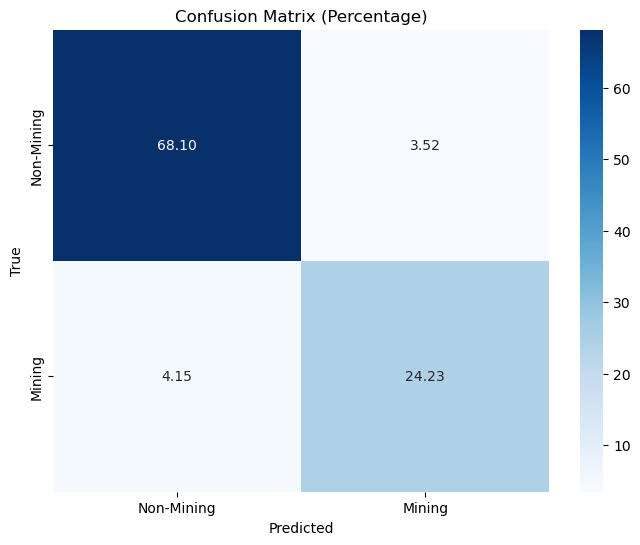

In [20]:
import numpy as np
from sklearn.metrics import confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize lists for true labels and predictions
true_labels = []
pred_labels = []

# Iterate through the testset for all steps
for step in range(steps):
    # Use `next()` to get the images and masks from the generator
    images, masks = next(testset)  # Assuming `testset` is a generator
    
    # Predict the masks using the model
    predictions = model.predict(images, verbose=0)  # Disable verbose for cleaner output
    
    # Binarize predictions with a threshold of 0.5
    pred_binary = (predictions > 0.5).astype(int)
    
    # Convert masks and predictions to NumPy arrays and flatten them
    true_flat = masks.numpy().flatten()
    pred_flat = pred_binary.flatten()
    
    # Append the flattened arrays to the lists
    true_labels.extend(true_flat)
    pred_labels.extend(pred_flat)

# Convert lists to numpy arrays
true_labels = np.array(true_labels)
pred_labels = np.array(pred_labels)

# Generate the confusion matrix
cf_matrix = confusion_matrix(true_labels, pred_labels, labels=[0, 1], normalize='all')

# Convert confusion matrix to a DataFrame for better visualization
list_labels_confusion = ['Non-Mining', 'Mining']  # Update labels based on your binary segmentation
df_matrix_all = pd.DataFrame(cf_matrix * 100, columns=list_labels_confusion, index=list_labels_confusion)

# Plot the confusion matrix as a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df_matrix_all, annot=True, fmt=".2f", cmap='Blues')  # ".2f" for percentage formatting
plt.title('Confusion Matrix (Percentage)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Save the confusion matrix plot if needed
# plt.savefig('confusion_matrix_binary_segmentation.jpg', bbox_inches='tight', dpi=300)


# Prediction Visualization

Processing all test images to find true best/worst results... Please wait.
Displaying visualization...


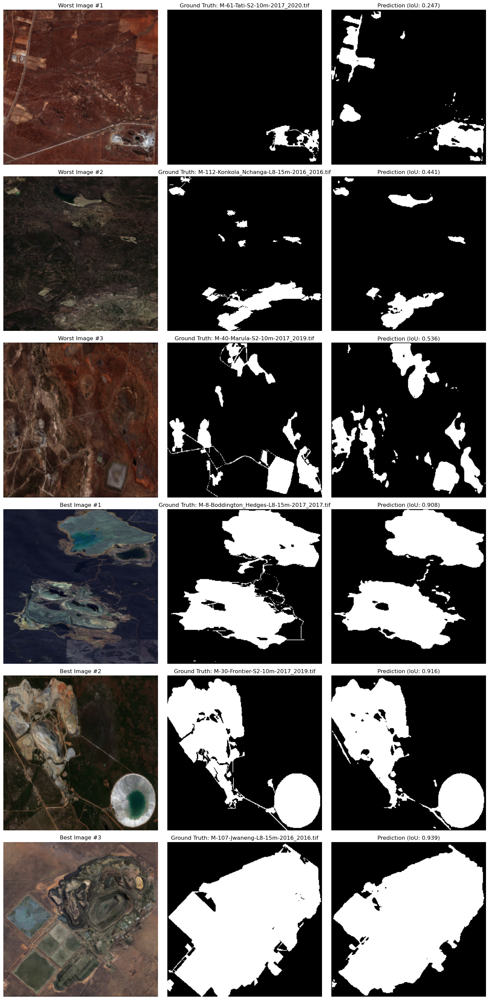

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2
import rasterio

# --- User-defined variables (IMPORTANT) ---
# 1. Make sure a trained `model` object is loaded before running this script.
# 2. Replace with the actual input size your model expects.
height = 256  # Replace with your model's input height
width = 256   # Replace with your model's input width
MODEL_INPUT_SIZE = (width, height)

# --- Define paths ---
test_img_path = ''
test_mask_path = ''

# --- Load file lists ---
image_files = sorted([f for f in os.listdir(test_img_path) if f.endswith('.tif')])
mask_files = sorted([f for f in os.listdir(test_mask_path) if f.endswith('.tif')])

assert len(image_files) == len(mask_files), "The number of images and masks do not match!"

image_mask_pairs = [(os.path.join(test_img_path, img), os.path.join(test_mask_path, mask))
                    for img, mask in zip(image_files, mask_files)]

# This list will store the results for ALL valid images
results = []
print("Processing all test images to find true best/worst results... Please wait.")

# --- Compute IoU for ALL valid predictions ---
for img_path, mask_path in image_mask_pairs:
    ground_truth_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    
    # Skip this pair if the mask has no positive pixels
    if ground_truth_mask is None or not np.any(ground_truth_mask == 1):
        continue

    # --- Pre-process image ---
    with rasterio.open(img_path) as src:
        img_bands = src.read()
    original_img_rgbnir = np.moveaxis(img_bands, 0, -1) / 255.0
    
    # We only need the RGB channels for visualization
    original_img_rgb = original_img_rgbnir[:, :, :3]
    
    # --- Resize for model and visualization ---
    resized_img_rgbnir = cv2.resize(original_img_rgbnir, MODEL_INPUT_SIZE)
    resized_img_rgb = resized_img_rgbnir[:, :, :3]
    resized_mask = cv2.resize(ground_truth_mask, MODEL_INPUT_SIZE, interpolation=cv2.INTER_NEAREST)

    # --- Predict and calculate IoU ---
    input_img = np.expand_dims(resized_img_rgbnir, axis=0)
    prediction = model.predict(input_img, verbose=0)
    pred_binary = (prediction[0, :, :, 0] > 0.5).astype(np.uint8)

    intersection = np.logical_and(resized_mask, pred_binary).sum()
    union = np.logical_or(resized_mask, pred_binary).sum()
    iou_score = intersection / union if union > 0 else 0.0
    
    # Append the results needed for visualization
    results.append((iou_score, img_path, resized_img_rgb, resized_mask, pred_binary))

# --- Select and Visualize the True Best and Worst ---
if len(results) < 6:
    print(f"Warning: Only found {len(results)} images with positive masks. Visualizing all of them.")
    selected_results = results
else:
    # Sort results by IoU score
    results.sort(key=lambda x: x[0])
    worst_results = results[:3]  # 3 lowest IoUs
    best_results = results[-3:]   # 3 highest IoUs
    selected_results = worst_results + best_results

if not selected_results:
    raise ValueError("No images with positive class pixels were found to visualize!")

# --- Visualization ---
print("Displaying visualization...")
plt.figure(figsize=(15, len(selected_results) * 5))
for i, (iou_score, img_path, resized_img_rgb, resized_mask, pred_binary) in enumerate(selected_results):
    # Determine title prefix (Worst or Best)
    title_prefix = "Worst" if i < 3 and len(results) >= 6 else "Best" if len(results) >= 6 else "Result"

    # --- Plot Image ---
    plt.subplot(len(selected_results), 3, i * 3 + 1)
    plt.imshow(resized_img_rgb)
    plt.title(f'{title_prefix} Image #{i % 3 + 1}')
    plt.axis('off')
    
    # --- Plot Ground Truth Mask ---
    plt.subplot(len(selected_results), 3, i * 3 + 2)
    plt.imshow(resized_mask, cmap='gray')
    plt.title(f'Ground Truth: {os.path.basename(img_path)}')
    plt.axis('off')
    
    # --- Plot Predicted Mask ---
    plt.subplot(len(selected_results), 3, i * 3 + 3)
    plt.imshow(pred_binary, cmap='gray')
    plt.title(f'Prediction (IoU: {iou_score:.3f})')
    plt.axis('off')

plt.tight_layout()
plt.show()

Processing all test images... Please wait.
Displaying visualization for all 41 valid results...





In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2
import rasterio

# --- User-defined variables (IMPORTANT) ---
# 1. Make sure a trained `model` object is loaded before running this script.
# 2. Replace with the actual input size your model expects.
height = 256  # Replace with your model's input height
width = 256   # Replace with your model's input width
MODEL_INPUT_SIZE = (width, height)

# --- Define paths ---
test_img_path = ''
test_mask_path = ''

# --- Load file lists ---
image_files = sorted([f for f in os.listdir(test_img_path) if f.endswith('.tif')])
mask_files = sorted([f for f in os.listdir(test_mask_path) if f.endswith('.tif')])

assert len(image_files) == len(mask_files), "The number of images and masks do not match!"

image_mask_pairs = [(os.path.join(test_img_path, img), os.path.join(test_mask_path, mask))
                    for img, mask in zip(image_files, mask_files)]

# This list will store the results for ALL valid images
results = []
print("Processing all test images... Please wait.")

# --- Compute IoU for ALL valid predictions ---
for img_path, mask_path in image_mask_pairs:
    ground_truth_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    
    # Skip this pair if the mask has no positive pixels
    if ground_truth_mask is None or not np.any(ground_truth_mask == 1):
        continue

    # --- Pre-process image ---
    with rasterio.open(img_path) as src:
        img_bands = src.read()
    original_img_rgbnir = np.moveaxis(img_bands, 0, -1) / 255.0
    
    # We only need the RGB channels for visualization
    original_img_rgb = original_img_rgbnir[:, :, :3]
    
    # --- Resize for model and visualization ---
    resized_img_rgbnir = cv2.resize(original_img_rgbnir, MODEL_INPUT_SIZE)
    resized_img_rgb = resized_img_rgbnir[:, :, :3]
    resized_mask = cv2.resize(ground_truth_mask, MODEL_INPUT_SIZE, interpolation=cv2.INTER_NEAREST)

    # --- Predict and calculate IoU ---
    input_img = np.expand_dims(resized_img_rgbnir, axis=0)
    prediction = model.predict(input_img, verbose=0)
    pred_binary = (prediction[0, :, :, 0] > 0.5).astype(np.uint8)

    intersection = np.logical_and(resized_mask, pred_binary).sum()
    union = np.logical_or(resized_mask, pred_binary).sum()
    iou_score = intersection / union if union > 0 else 0.0
    
    # Append the results needed for visualization
    results.append((iou_score, img_path, resized_img_rgb, resized_mask, pred_binary))

# --- Check if any valid results were found ---
if not results:
    raise ValueError("No images with positive class pixels were found to visualize!")

# --- Sort results by IoU score for an ordered display (worst to best) ---
results.sort(key=lambda x: x[0])

# --- Visualization of ALL results ---
print(f"Displaying visualization for all {len(results)} valid results...")
plt.figure(figsize=(15, len(results) * 5))
for i, (iou_score, img_path, resized_img_rgb, resized_mask, pred_binary) in enumerate(results):
    # --- Plot Image ---
    plt.subplot(len(results), 3, i * 3 + 1)
    plt.imshow(resized_img_rgb)
    plt.title(f'Image #{i + 1}')
    plt.axis('off')
    
    # --- Plot Ground Truth Mask ---
    plt.subplot(len(results), 3, i * 3 + 2)
    plt.imshow(resized_mask, cmap='gray')
    plt.title(f'Ground Truth: {os.path.basename(img_path)}')
    plt.axis('off')
    
    # --- Plot Predicted Mask ---
    plt.subplot(len(results), 3, i * 3 + 3)
    plt.imshow(pred_binary, cmap='gray')
    plt.title(f'Prediction (IoU: {iou_score:.3f})')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import os
import cv2
import rasterio


height = 256  # Replace with your model's input height
width = 256   # Replace with your model's input width
MODEL_INPUT_SIZE = (width, height)

# --- Define paths ---
test_img_path = ''
test_mask_path = ''

# --- Load file lists ---
image_files = sorted([f for f in os.listdir(test_img_path) if f.endswith('.tif')])
mask_files = sorted([f for f in os.listdir(test_mask_path) if f.endswith('.tif')])

# Ensure the number of images matches the number of masks
assert len(image_files) == len(mask_files), "The number of images and masks do not match!"

# --- Main processing loop ---
# This list will store tuples of (iou_score, image_filename) to be sorted later
results_list = [] 
print("Processing all test images... Please wait.")

# Iterate through every image and mask pair
for img_file, mask_file in zip(image_files, mask_files):
    img_path = os.path.join(test_img_path, img_file)
    mask_path = os.path.join(test_mask_path, mask_file)

    ground_truth_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    
    if ground_truth_mask is None:
        continue
    if not np.any(ground_truth_mask == 1):
        continue

    with rasterio.open(img_path) as src:
        img_bands = src.read()
    
    original_img_rgbnir = np.moveaxis(img_bands, 0, -1) / 255.0
    resized_img_rgbnir = cv2.resize(original_img_rgbnir, MODEL_INPUT_SIZE)
    
    resized_mask = cv2.resize(ground_truth_mask, MODEL_INPUT_SIZE, interpolation=cv2.INTER_NEAREST)

    input_img = np.expand_dims(resized_img_rgbnir, axis=0)
    prediction = model.predict(input_img, verbose=0)
    pred_binary = (prediction[0, :, :, 0] > 0.5).astype(np.uint8)

    intersection = np.logical_and(resized_mask, pred_binary).sum()
    union = np.logical_or(resized_mask, pred_binary).sum()
    iou_score = intersection / union if union > 0 else 0.0
    
    # Store the result instead of printing it immediately
    results_list.append((iou_score, img_file))

# --- Sort, Display, and Calculate Final Results ---
if not results_list:
    print("\nNo images with positive masks were found. No scores to display.")
else:
    # Sort the list of results based on the IoU score (the first element in the tuple)
    results_list.sort(key=lambda x: x[0])

    print("\n--- Individual IoU Scores (Sorted from Lowest to Highest) ---")
    all_iou_scores = []
    for score, filename in results_list:
        # Print each item from the sorted list
        print(f"IoU: {score:<6.4f} | Image: {filename}")
        all_iou_scores.append(score)

    # --- Final Mean IoU Calculation ---
    mean_iou = np.mean(all_iou_scores)
    print("\n" + "="*45)
    print(f"📊 Final Mean IoU (mIoU): {mean_iou:.4f}")
    print(f"   (Calculated from {len(all_iou_scores)} images with positive masks)")
    print("="*45)

Processing all test images... Please wait.

--- Individual IoU Scores (Sorted from Lowest to Highest) ---
IoU: 0.2472 | Image: M-61-Tati-S2-10m-2017_2020.tif
IoU: 0.4413 | Image: M-112-Konkola_Nchanga-L8-15m-2016_2016.tif
IoU: 0.5364 | Image: M-40-Marula-S2-10m-2017_2019.tif
IoU: 0.5747 | Image: M-77-Bingham_Canyon-L8-15m-2016_2016.tif
IoU: 0.6266 | Image: M-45-Mount_Isa-L8-15m-2017_2017.tif
IoU: 0.6343 | Image: M-162-Gabriela_Mistral_Minera_Gaby-L8-15m-2015_2015.tif
IoU: 0.6499 | Image: M-174-Los_Pelambres-L8-15m-2015_2015.tif
IoU: 0.6603 | Image: M-15-Centinela-L8-15m-2017_2017.tif
IoU: 0.6799 | Image: M-120-Milpillas-L8-15m-2016_2016.tif
IoU: 0.6924 | Image: M-6-Bafokeng_Rasimone-S2-10m-2017_2020.tif
IoU: 0.6926 | Image: M-10-Bulyanhulu-S2-10m-2017_2019.tif
IoU: 0.6952 | Image: M-93-Damtshaa-L8-15m-2016_2016.tif
IoU: 0.6961 | Image: M-144-Spence-L8-15m-2016_2016.tif
IoU: 0.7018 | Image: M-24-Cosala_Nuestra_Senora_Zone120-S2-10m-2017_2020.tif
IoU: 0.7118 | Image: M-159-Chirano-L8-15m

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2
import rasterio

# --- Helper function for visualization ---
def contrast_stretch(img):
    """Performs contrast stretching on a 3-band image for better visualization."""
    stretched = np.zeros_like(img, dtype=np.float32)
    # Stretch each band to the 2nd and 98th percentiles
    for i in range(img.shape[2]):
        p2, p98 = np.percentile(img[:, :, i], (2, 98))
        stretched[:, :, i] = np.clip((img[:, :, i] - p2) / (p98 - p2), 0, 1)
    return stretched

height = 256  # Replace with your model's input height
width = 256   # Replace with your model's input width
MODEL_INPUT_SIZE = (width, height)

# 3. Define a directory to save the output images
output_dir = 'visualization_results_DTAV2'
os.makedirs(output_dir, exist_ok=True) # Create directory if it doesn't exist

# Define the path to the test images and masks
test_img_path = ''
test_mask_path = ''

# --- Load file lists ---
image_files = sorted([f for f in os.listdir(test_img_path) if f.endswith('.tif')])
mask_files = sorted([f for f in os.listdir(test_mask_path) if f.endswith('.tif')])

assert len(image_files) == len(mask_files), "The number of images and masks do not match!"

image_mask_pairs = [(os.path.join(test_img_path, img), os.path.join(test_mask_path, mask))
                    for img, mask in zip(image_files, mask_files)]

# This list will store the results for ALL valid images
results = []
print("Processing all test images... Please wait.")

# --- Compute IoU for ALL valid predictions ---
for img_path, mask_path in image_mask_pairs:
    ground_truth_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    
    if ground_truth_mask is None or not np.any(ground_truth_mask == 1):
        continue

    with rasterio.open(img_path) as src:
        # Ensure we read all 6 bands
        img_bands = src.read()
        if img_bands.shape[0] < 6:
            print(f"Warning: Skipping {os.path.basename(img_path)} because it has fewer than 6 bands.")
            continue
            
    original_all_bands = np.moveaxis(img_bands, 0, -1) / 255.0
    
    resized_all_bands = cv2.resize(original_all_bands, MODEL_INPUT_SIZE)
    resized_mask = cv2.resize(ground_truth_mask, MODEL_INPUT_SIZE, interpolation=cv2.INTER_NEAREST)

    input_img = np.expand_dims(resized_all_bands, axis=0)
    prediction = model.predict(input_img, verbose=0)
    
    # This logic to find the segmentation output remains the same
    segmentation_prediction_tensor = None
    if isinstance(prediction, dict):
        for key in prediction.keys():
            if 'segmentation' in key.lower() or 'mask' in key.lower() or 'output' in key.lower():
                segmentation_prediction_tensor = prediction[key]
                break
        if segmentation_prediction_tensor is None:
             raise ValueError(f"Could not find segmentation key in predictions dict. Keys: {prediction.keys()}")
    elif isinstance(prediction, (list, tuple)):
        segmentation_prediction_tensor = prediction[1] if len(prediction) > 1 else prediction[0]
    else:
        segmentation_prediction_tensor = prediction
    
    pred_binary = (segmentation_prediction_tensor[0, :, :, 0] > 0.5).astype(np.uint8)

    intersection = np.logical_and(resized_mask, pred_binary).sum()
    union = np.logical_or(resized_mask, pred_binary).sum()
    iou_score = intersection / union if union > 0 else 0.0
    
    # Append all 6 resized bands for later visualization
    results.append((iou_score, img_path, resized_all_bands, resized_mask, pred_binary))

# --- Sort and Save Visualization for ALL Results ---
if not results:
    raise ValueError("No images with positive class pixels were found to visualize!")

results.sort(key=lambda x: x[0]) # Sort by IoU score (lowest to highest)
print(f"Found {len(results)} images with positive masks. Saving all visualizations to '{output_dir}/'")

for i, (iou_score, img_path, resized_all_bands, resized_mask, pred_binary) in enumerate(results):
    
    # --- Create Band Composites for Visualization ---
    # Assuming band order: 0:R, 1:G, 2:B, 3:NIR, 4:SWIR1, 5:SWIR2
    
    # 1. True Color (RGB)
    rgb_vis = resized_all_bands[:, :, [0, 1, 2]]
    
    # 2. False Color Infrared (NIR, R, G)
    false_color_nir_vis = resized_all_bands[:, :, [3, 0, 1]]
    
    # 3. False Color SWIR (SWIR2, SWIR1, R)
    false_color_swir_vis = resized_all_bands[:, :, [5, 4, 0]]

    # --- Plotting ---
    # Create a new figure for each result with 5 subplots
    fig, axes = plt.subplots(1, 5, figsize=(25, 5))
    fig.suptitle(f"Result #{i+1}: {os.path.basename(img_path)}", fontsize=16)
    
    # Plot 1: True Color
    axes[0].imshow(contrast_stretch(rgb_vis))
    axes[0].set_title('True Color (RGB)')
    axes[0].axis('off')
    
    # Plot 2: False Color (NIR)
    axes[1].imshow(contrast_stretch(false_color_nir_vis))
    axes[1].set_title('False Color (NIR, R, G)')
    axes[1].axis('off')
    
    # Plot 3: False Color (SWIR)
    axes[2].imshow(contrast_stretch(false_color_swir_vis))
    axes[2].set_title('False Color (SWIR2, SWIR1, R)')
    axes[2].axis('off')

    # Plot 4: Ground Truth Mask
    axes[3].imshow(resized_mask, cmap='gray')
    axes[3].set_title('Ground Truth')
    axes[3].axis('off')
    
    # Plot 5: Predicted Mask
    axes[4].imshow(pred_binary, cmap='gray')
    axes[4].set_title(f'Prediction (IoU: {iou_score:.3f})')
    axes[4].axis('off')
    
    # Adjust layout and save the figure to a file
    plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust for suptitle
    output_filename = f"result_{i+1:04d}_iou_{iou_score:.3f}.png"
    plt.savefig(os.path.join(output_dir, output_filename))
    
    # Close the figure to free memory
    plt.close(fig)

print("✅ All visualization files have been saved successfully.")

Processing all test images... Please wait.
Found 41 images with positive masks. Saving all visualizations to 'visualization_results_DTAV2/'
✅ All visualization files have been saved successfully.


In [ ]:
import numpy as np
import os
import cv2
import rasterio


height = 256  # Replace with your model's input height
width = 256   # Replace with your model's input width
MODEL_INPUT_SIZE = (width, height)

# --- Define paths ---
test_img_path = ''
test_mask_path = ''

# --- Load file lists ---
image_files = sorted([f for f in os.listdir(test_img_path) if f.endswith('.tif')])
mask_files = sorted([f for f in os.listdir(test_mask_path) if f.endswith('.tif')])

# Ensure the number of images matches the number of masks
assert len(image_files) == len(mask_files), "The number of images and masks do not match!"

# --- Main processing loop ---
# This list will store tuples of (iou_score, accuracy, f1_score, image_filename)
results_list = [] 
print("Processing all test images... Please wait.")

# Iterate through every image and mask pair
for img_file, mask_file in zip(image_files, mask_files):
    img_path = os.path.join(test_img_path, img_file)
    mask_path = os.path.join(test_mask_path, mask_file)

    ground_truth_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    
    if ground_truth_mask is None:
        continue
    # Skip images that don't have a positive class in the mask
    if not np.any(ground_truth_mask == 1):
        continue

    with rasterio.open(img_path) as src:
        img_bands = src.read()
    
    original_img_rgbnir = np.moveaxis(img_bands, 0, -1) / 255.0
    resized_img_rgbnir = cv2.resize(original_img_rgbnir, MODEL_INPUT_SIZE)
    
    resized_mask = cv2.resize(ground_truth_mask, MODEL_INPUT_SIZE, interpolation=cv2.INTER_NEAREST)

    input_img = np.expand_dims(resized_img_rgbnir, axis=0)
    prediction = model.predict(input_img, verbose=0)
    pred_binary = (prediction[0, :, :, 0] > 0.5).astype(np.uint8)

    # --- Metrics Calculation ---
    # Epsilon to avoid division by zero
    epsilon = 1e-6
    
    # Intersection over Union (IoU)
    intersection = np.logical_and(resized_mask, pred_binary).sum()
    union = np.logical_or(resized_mask, pred_binary).sum()
    iou_score = intersection / (union + epsilon)
    
    # Accuracy
    accuracy = np.mean(resized_mask == pred_binary)

    # F1-Score
    # True Positives (TP) is the same as intersection
    tp = intersection
    # False Positives (FP)
    fp = np.logical_and(pred_binary, np.logical_not(resized_mask)).sum()
    # False Negatives (FN)
    fn = np.logical_and(np.logical_not(pred_binary), resized_mask).sum()
    
    precision = tp / (tp + fp + epsilon)
    recall = tp / (tp + fn + epsilon)
    f1_score = 2 * (precision * recall) / (precision + recall + epsilon)
    
    # Store all results together
    results_list.append((iou_score, accuracy, f1_score, img_file))

# --- Sort, Display, and Calculate Final Results ---
if not results_list:
    print("\nNo images with positive masks were found. No scores to display.")
else:
    # Sort the list of results based on the IoU score (lowest to highest)
    results_list.sort(key=lambda x: x[0])

    print("\n--- Individual Scores (Sorted by IoU) ---")
    all_iou_scores = []
    all_accuracy_scores = []
    all_f1_scores = []
    
    for iou, acc, f1, filename in results_list:
        # Print each item from the sorted list
        print(f"IoU: {iou:<6.4f} | Accuracy: {acc:<6.4f} | F1: {f1:<6.4f} | Image: {filename}")
        all_iou_scores.append(iou)
        all_accuracy_scores.append(acc)
        all_f1_scores.append(f1)

    # --- Final Mean Scores Calculation ---
    mean_iou = np.mean(all_iou_scores)
    mean_accuracy = np.mean(all_accuracy_scores)
    mean_f1 = np.mean(all_f1_scores)
    
    print("\n" + "="*55)
    print(f"📊 Final Mean Scores (Calculated from {len(results_list)} images):")
    print(f"   - Mean IoU (mIoU):       {mean_iou:.4f}")
    print(f"   - Mean Accuracy:         {mean_accuracy:.4f}")
    print(f"   - Mean F1-Score (mF1):   {mean_f1:.4f}")
    print("="*55)

Processing all test images... Please wait.

--- Individual Scores (Sorted by IoU) ---
IoU: 0.2472 | Accuracy: 0.9285 | F1: 0.3964 | Image: M-61-Tati-S2-10m-2017_2020.tif
IoU: 0.4413 | Accuracy: 0.9417 | F1: 0.6123 | Image: M-112-Konkola_Nchanga-L8-15m-2016_2016.tif
IoU: 0.5364 | Accuracy: 0.9108 | F1: 0.6982 | Image: M-40-Marula-S2-10m-2017_2019.tif
IoU: 0.5747 | Accuracy: 0.8582 | F1: 0.7299 | Image: M-77-Bingham_Canyon-L8-15m-2016_2016.tif
IoU: 0.6266 | Accuracy: 0.9369 | F1: 0.7704 | Image: M-45-Mount_Isa-L8-15m-2017_2017.tif
IoU: 0.6343 | Accuracy: 0.8281 | F1: 0.7763 | Image: M-162-Gabriela_Mistral_Minera_Gaby-L8-15m-2015_2015.tif
IoU: 0.6499 | Accuracy: 0.8471 | F1: 0.7878 | Image: M-174-Los_Pelambres-L8-15m-2015_2015.tif
IoU: 0.6603 | Accuracy: 0.8865 | F1: 0.7954 | Image: M-15-Centinela-L8-15m-2017_2017.tif
IoU: 0.6799 | Accuracy: 0.9591 | F1: 0.8094 | Image: M-120-Milpillas-L8-15m-2016_2016.tif
IoU: 0.6924 | Accuracy: 0.9370 | F1: 0.8182 | Image: M-6-Bafokeng_Rasimone-S2-10m-2